# Libraries


In [12]:
%pip install xgboost imbalanced-learn scikit-learn pandas numpy matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    auc,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42

# Assumed illustrative cost of investigating a false alarm
FP_COST = 2.0

# Loading data


In [14]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/validation.csv")
test_df = pd.read_csv("../data/test.csv")

print("Training data:", train_df.shape)
print("Validation data:", val_df.shape)
print("Test data:", test_df.shape)

Training data: (198608, 31)
Validation data: (42559, 31)
Test data: (42559, 31)


In [15]:
# Check target distribution
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} class counts:")
    print(data["Class"].value_counts())
    print(f"{name} fraud rate: {data['Class'].mean():.4%}")

# The standard credit-card dataset uses:
# Class = 0 for legitimate transactions
# Class = 1 for fraudulent transactions
assert "Class" in train_df.columns
assert "Amount" in test_df.columns


Training class counts:
Class
0    198242
1       366
Name: count, dtype: int64
Training fraud rate: 0.1843%

Validation class counts:
Class
0    42504
1       55
Name: count, dtype: int64
Validation fraud rate: 0.1292%

Test class counts:
Class
0    42507
1       52
Name: count, dtype: int64
Test fraud rate: 0.1222%


# Separating features and target


In [16]:
# Separate input features from the fraud label
X_train = train_df.drop(columns=["Class"]).copy()
y_train = train_df["Class"].astype(int).copy()

X_val = val_df.drop(columns=["Class"]).copy()
y_val = val_df["Class"].astype(int).copy()

X_test = test_df.drop(columns=["Class"]).copy()
y_test = test_df["Class"].astype(int).copy()

# Ensure columns are in the same order across all datasets
X_val = X_val.reindex(columns=X_train.columns)
X_test = X_test.reindex(columns=X_train.columns)

# Keep the original test transaction amounts for cost calculations
test_amounts = test_df["Amount"].reset_index(drop=True).astype(float)

# Basic checks
assert X_train.columns.tolist() == X_val.columns.tolist()
assert X_train.columns.tolist() == X_test.columns.tolist()

print("Number of features:", X_train.shape[1])
print("Training fraud cases:", int(y_train.sum()))
print("Training legitimate cases:", int((y_train == 0).sum()))

Number of features: 30
Training fraud cases: 366
Training legitimate cases: 198242


# Calculate Imbalance Weight

In [17]:
fraud_count = int((y_train == 1).sum())
genuine_count = int((y_train == 0).sum())

if fraud_count == 0:
    raise ValueError("No fraud examples found in the training set.")

scale_pos_weight = genuine_count / fraud_count

print("Legitimate transactions:", genuine_count)
print("Fraudulent transactions:", fraud_count)
print("scale_pos_weight:", round(scale_pos_weight, 2))

Legitimate transactions: 198242
Fraudulent transactions: 366
scale_pos_weight: 541.64


# Model Building - Cost-sensitive

In [19]:
cost_sensitive_model = Pipeline([
    ("scaler", StandardScaler()),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train only on the training split
cost_sensitive_model.fit(X_train, y_train)

# Obtain fraud probabilities on validation and test sets
val_prob_cost = cost_sensitive_model.predict_proba(X_val)[:, 1]
test_prob_cost = cost_sensitive_model.predict_proba(X_test)[:, 1]

print("Cost-sensitive XGBoost training completed.")

Cost-sensitive XGBoost training completed.


# Business-cost calculation

## Cost Function

In [20]:
def calculate_business_cost(y_true, predictions, amounts):
    """
    Calculate illustrative business cost.

    FP cost = $2 per legitimate transaction flagged as fraud.
    FN cost = transaction Amount for each missed fraud.
    """

    # Convert inputs to arrays so row-wise indexing is consistent
    y_true = np.asarray(y_true)
    predictions = np.asarray(predictions)
    amounts = np.asarray(amounts, dtype=float)

    # False positives: actual legitimate, predicted fraud
    fp_mask = (y_true == 0) & (predictions == 1)
    fp_count = int(fp_mask.sum())
    fp_cost = fp_count * FP_COST

    # False negatives: actual fraud, predicted legitimate
    fn_mask = (y_true == 1) & (predictions == 0)
    fn_count = int(fn_mask.sum())
    fn_cost = float(amounts[fn_mask].sum())

    total_cost = fp_cost + fn_cost

    return {
        "FP": fp_count,
        "FN": fn_count,
        "FP_cost": fp_cost,
        "FN_estimated_loss": fn_cost,
        "total_cost": total_cost
    }

## Choose a threshold using validation data
Find the threshold with the lowest estimated validation cost.
Test data must not be used for threshold selection.

In [21]:
def find_best_threshold(y_true, probabilities, amounts):
    results = []

    thresholds = np.arange(0.01, 1.00, 0.01)

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        costs = calculate_business_cost(
            y_true,
            predictions,
            amounts
        )

        results.append({
            "threshold": float(threshold),
            **costs,
            "precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_true, predictions, zero_division=0
            )
        })

    results_df = pd.DataFrame(results)

    # Minimize cost; when tied, prefer higher recall
    results_df = results_df.sort_values(
        ["total_cost", "recall", "precision"],
        ascending=[True, False, False]
    ).reset_index(drop=True)

    return float(results_df.iloc[0]["threshold"]), results_df


val_amounts = val_df["Amount"].to_numpy(dtype=float)

threshold_cost, cost_threshold_results = find_best_threshold(
    y_val,
    val_prob_cost,
    val_amounts
)

print("Best validation threshold:", threshold_cost)
print("\nBest threshold details:")
print(cost_threshold_results.iloc[0])

Best validation threshold: 0.05

Best threshold details:
threshold              0.050000
FP                    84.000000
FN                     7.000000
FP_cost              168.000000
FN_estimated_loss    161.550000
total_cost           329.550000
precision              0.363636
recall                 0.872727
Name: 0, dtype: float64


# Train Model - SMOTE + XGBoost

## Build and train the SMOTE model

In [22]:
# SMOTE needs at least two fraud examples in the training set
if fraud_count < 2:
    raise ValueError(
        "SMOTE requires at least two fraud examples in the training set."
    )

smote_neighbors = min(5, fraud_count - 1)

smote_model = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        random_state=RANDOM_STATE,
        k_neighbors=smote_neighbors
    )),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# SMOTE is applied only during fit on the training data
smote_model.fit(X_train, y_train)

# Validation and test data are not oversampled
val_prob_smote = smote_model.predict_proba(X_val)[:, 1]
test_prob_smote = smote_model.predict_proba(X_test)[:, 1]

print("SMOTE + XGBoost training completed.")

SMOTE + XGBoost training completed.


## Choose the SMOTE model's threshold

In [23]:
threshold_smote, smote_threshold_results = find_best_threshold(
    y_val,
    val_prob_smote,
    val_amounts
)

print("Best validation threshold for SMOTE:", threshold_smote)
print("\nBest threshold details:")
print(smote_threshold_results.iloc[0])

Best validation threshold for SMOTE: 0.86

Best threshold details:
threshold              0.860000
FP                     3.000000
FN                    12.000000
FP_cost                6.000000
FN_estimated_loss    403.560000
total_cost           409.560000
precision              0.934783
recall                 0.781818
Name: 0, dtype: float64


# Model Evaluation
Evaluate one model using a fixed validation-selected threshold.


In [ ]:
def evaluate_model(name, y_true, probabilities, threshold, amounts):

    predictions = (probabilities >= threshold).astype(int)

    # Ranking metrics use probabilities, not thresholded predictions
    average_precision = average_precision_score(y_true, probabilities)

    precision_curve, recall_curve, _ = precision_recall_curve(y_true, probabilities)

    trapezoidal_pr_auc = auc(recall_curve, precision_curve)

    # Threshold-dependent metrics
    precision = precision_score(y_true, predictions, zero_division=0)
    recall = recall_score(y_true, predictions, zero_division=0)
    f1 = f1_score(y_true, predictions, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()

    costs = calculate_business_cost(y_true, predictions, amounts)

    result = {
        "Model": name,
        "Threshold": threshold,
        "Average_Precision": average_precision,
        "Trapezoidal_PR_AUC": trapezoidal_pr_auc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        **costs
    }

    print(f"\n{'=' * 55}")
    print(name)
    print(f"{'=' * 55}")
    print(classification_report(y_true, predictions, target_names=["Legitimate", "Fraud"], zero_division=0))
    print("Confusion matrix:")
    print(np.array([[tn, fp], [fn, tp]]))
    print("Average Precision:", round(average_precision, 6))
    print("Trapezoidal PR-AUC:", round(trapezoidal_pr_auc, 6))
    print("Estimated total business cost:", round(costs["total_cost"], 2))

    return result, predictions

## Run the final test evaluation

In [ ]:
# Use the thresholds selected on validation data
test_amounts_array = test_amounts.to_numpy()

cost_result, cost_predictions = evaluate_model(
    "Cost-sensitive XGBoost",
    y_test,
    test_prob_cost,
    threshold_cost,
    test_amounts_array
)

smote_result, smote_predictions = evaluate_model(
    "SMOTE + XGBoost",
    y_test,
    test_prob_smote,
    threshold_smote,
    test_amounts_array
)

comparison = pd.DataFrame([cost_result, smote_result])

print("\nFINAL TEST-SET COMPARISON")
display(comparison.round(4))


Cost-sensitive XGBoost
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42507
       Fraud       0.36      0.77      0.49        52

    accuracy                           1.00     42559
   macro avg       0.68      0.88      0.74     42559
weighted avg       1.00      1.00      1.00     42559

Confusion matrix:
[[42436    71]
 [   12    40]]
Average Precision: 0.763034
Trapezoidal PR-AUC: 0.762709
Estimated total business cost: 1880.1

SMOTE + XGBoost
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42507
       Fraud       0.74      0.75      0.74        52

    accuracy                           1.00     42559
   macro avg       0.87      0.87      0.87     42559
weighted avg       1.00      1.00      1.00     42559

Confusion matrix:
[[42493    14]
 [   13    39]]
Average Precision: 0.76627
Trapezoidal PR-AUC: 0.765985
Estimated total business cost: 2400.4

FINAL TEST-SET CO

,Model,Threshold,Average_Precision,Trapezoidal_PR_AUC,Precision,Recall,F1,TN,FP,FN,TP,FP_cost,FN_estimated_loss,total_cost
0,Cost-sensitive XGBoost,0.05,0.7630,0.7627,0.3604,0.7692,0.4908,42436,71,12,40,142.0,1738.1,1880.1
1,SMOTE + XGBoost,0.86,0.7663,0.7660,0.7358,0.7500,0.7429,42493,14,13,39,28.0,2372.4,2400.4


# Visualize the results - PR-AUC

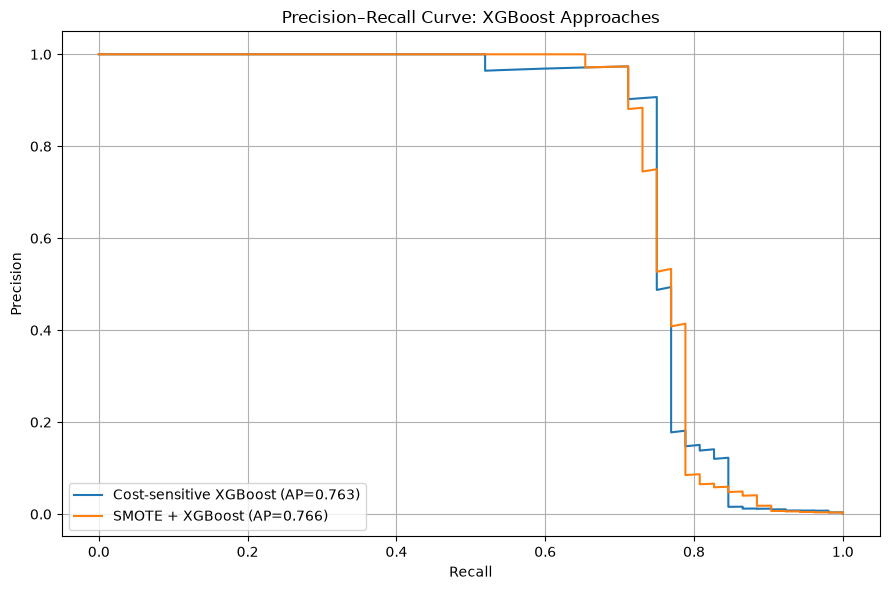

In [27]:
# Calculate precision-recall curves for both models
cost_precision, cost_recall, _ = precision_recall_curve(
    y_test, test_prob_cost
)

smote_precision, smote_recall, _ = precision_recall_curve(
    y_test, test_prob_smote
)

plt.figure(figsize=(9, 6))

plt.plot(
    cost_recall,
    cost_precision,
    label=f"Cost-sensitive XGBoost (AP={cost_result['Average_Precision']:.3f})"
)

plt.plot(
    smote_recall,
    smote_precision,
    label=f"SMOTE + XGBoost (AP={smote_result['Average_Precision']:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve: XGBoost Approaches")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()